In [29]:
import sys

print("Version de Python :", sys.version)
print("Emplacement de Python :", sys.executable)

Version de Python : 3.13.5 | packaged by Anaconda, Inc. | (main, Jun 12 2025, 16:37:03) [MSC v.1929 64 bit (AMD64)]
Emplacement de Python : C:\Users\LENOVO\anaconda3\python.exe


In [30]:
import pandas as pd
import numpy as np
import matplotlib
import seaborn as sns

print("Pandas :", pd.__version__)
print("NumPy :", np.__version__)
print("Matplotlib :", matplotlib.__version__)
print("Seaborn :", sns.__version__)

print("\nToutes les bibliothèques sont prêtes !")

Pandas : 2.2.3
NumPy : 2.1.3
Matplotlib : 3.10.0
Seaborn : 0.13.2

Toutes les bibliothèques sont prêtes !


In [31]:
from pathlib import Path

print("Dossier de travail actuel :")
print(Path.cwd())

Dossier de travail actuel :
C:\Users\LENOVO\Bureau\Projets\OIBSIP\DataAnalytics-L1-EDARetailSales


In [32]:
from pathlib import Path

base_dir = Path.home() / "Bureau" / "Projets" / "OIBSIP"
project_dir = base_dir / "DataAnalytics-L1-EDARetailSales"

data_dir = project_dir / "data"
outputs_dir = project_dir / "outputs"

data_dir.mkdir(parents=True, exist_ok=True)
outputs_dir.mkdir(parents=True, exist_ok=True)

print("Projet :", project_dir)
print("Dossier des données :", data_dir)
print("Dossier des résultats :", outputs_dir)

Projet : C:\Users\LENOVO\Bureau\Projets\OIBSIP\DataAnalytics-L1-EDARetailSales
Dossier des données : C:\Users\LENOVO\Bureau\Projets\OIBSIP\DataAnalytics-L1-EDARetailSales\data
Dossier des résultats : C:\Users\LENOVO\Bureau\Projets\OIBSIP\DataAnalytics-L1-EDARetailSales\outputs


In [33]:
import pandas as pd
from pathlib import Path

base_dir = Path.home() / "Bureau" / "Projets" / "OIBSIP"
project_dir = base_dir / "DataAnalytics-L1-EDARetailSales"
data_file = project_dir / "data" / "retail_sales_dataset.csv"

df = pd.read_csv(data_file)

print("Données chargées avec succès !")
print("Nombre de lignes et de colonnes :", df.shape)

display(df.head())

Données chargées avec succès !
Nombre de lignes et de colonnes : (1000, 9)


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [34]:
print("Noms des colonnes :")
print(df.columns.tolist())

print("\nTypes des colonnes :")
print(df.dtypes)

print("\nValeurs manquantes :")
print(df.isnull().sum())

Noms des colonnes :
['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']

Types des colonnes :
Transaction ID       int64
Date                object
Customer ID         object
Gender              object
Age                  int64
Product Category    object
Quantity             int64
Price per Unit       int64
Total Amount         int64
dtype: object

Valeurs manquantes :
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64


In [35]:
# Convertir Date au format datetime
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Vérifier les doublons
print("Nombre de lignes dupliquées :", df.duplicated().sum())

# Vérifier les identifiants de transaction dupliqués
print(
    "Identifiants de transaction dupliqués :",
    df["Transaction ID"].duplicated().sum()
)

# Vérifier les dates invalides
print("Dates invalides :", df["Date"].isna().sum())

# Vérifier les valeurs numériques
print("\nStatistiques des colonnes numériques :")
display(df[["Age", "Quantity", "Price per Unit", "Total Amount"]].describe())

Nombre de lignes dupliquées : 0
Identifiants de transaction dupliqués : 0
Dates invalides : 0

Statistiques des colonnes numériques :


,Age,Quantity,Price per Unit,Total Amount
count,1000.00000,1000.000000,1000.000000,1000.000000
mean,41.39200,2.514000,179.890000,456.000000
std,13.68143,1.132734,189.681356,559.997632
min,18.00000,1.000000,25.000000,25.000000
25%,29.00000,1.000000,30.000000,60.000000
50%,42.00000,3.000000,50.000000,135.000000
75%,53.00000,4.000000,300.000000,900.000000
max,64.00000,4.000000,500.000000,2000.000000


In [36]:
# Calculer le montant attendu pour chaque transaction
df["Expected Amount"] = df["Quantity"] * df["Price per Unit"]

# Identifier les transactions dont le montant ne correspond pas
inconsistent = df[
    df["Total Amount"] != df["Expected Amount"]
]

print("Transactions avec un montant incohérent :", len(inconsistent))

display(
    inconsistent[
        ["Transaction ID", "Quantity", "Price per Unit",
         "Total Amount", "Expected Amount"]
    ].head(10)
)

Transactions avec un montant incohérent : 0


,Transaction ID,Quantity,Price per Unit,Total Amount,Expected Amount


In [37]:
# Indicateurs globaux
total_sales = df["Total Amount"].sum()
total_transactions = df["Transaction ID"].nunique()
average_transaction = df["Total Amount"].mean()
total_items = df["Quantity"].sum()

print(f"Montant total des ventes : {total_sales:,.2f}")
print(f"Nombre de transactions : {total_transactions}")
print(f"Montant moyen par transaction : {average_transaction:,.2f}")
print(f"Nombre total d'articles vendus : {total_items}")

Montant total des ventes : 456,000.00
Nombre de transactions : 1000
Montant moyen par transaction : 456.00
Nombre total d'articles vendus : 2514


In [38]:
sales_by_category = (
    df.groupby("Product Category")
      .agg(
          Total_Sales=("Total Amount", "sum"),
          Transactions=("Transaction ID", "nunique"),
          Items_Sold=("Quantity", "sum")
      )
      .sort_values("Total_Sales", ascending=False)
)

display(sales_by_category)

,Total_Sales,Transactions,Items_Sold
Product Category,,,
Electronics,156905,342,849
Clothing,155580,351,894
Beauty,143515,307,771


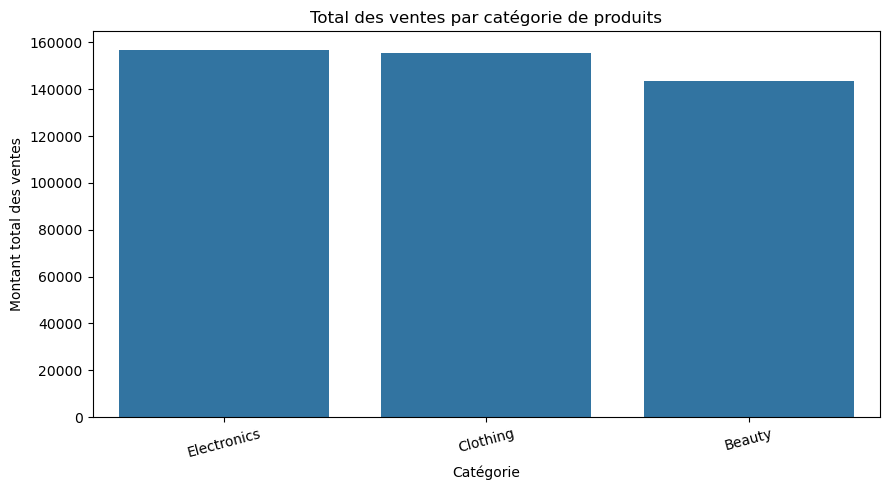

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.barplot(
    data=sales_by_category.reset_index(),
    x="Product Category",
    y="Total_Sales"
)

plt.title("Total des ventes par catégorie de produits")
plt.xlabel("Catégorie")
plt.ylabel("Montant total des ventes")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(
    outputs_dir / "sales_by_category.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [40]:
# Créer une colonne contenant le mois et l'année
df["YearMonth"] = df["Date"].dt.to_period("M")

# Calculer les ventes et les transactions par mois
monthly_sales = (
    df.groupby("YearMonth")
      .agg(
          Total_Sales=("Total Amount", "sum"),
          Transactions=("Transaction ID", "nunique"),
          Items_Sold=("Quantity", "sum")
      )
      .reset_index()
)

# Convertir le mois en texte pour faciliter l'affichage
monthly_sales["YearMonth"] = monthly_sales["YearMonth"].astype(str)

display(monthly_sales)

,YearMonth,Total_Sales,Transactions,Items_Sold
0,2023-01,35450,76,195
1,2023-02,44060,85,214
2,2023-03,28990,73,194
3,2023-04,33870,86,214
4,2023-05,53150,105,259
5,2023-06,36715,77,197
6,2023-07,35465,72,176
7,2023-08,36960,94,227
8,2023-09,23620,65,170
9,2023-10,46580,96,252


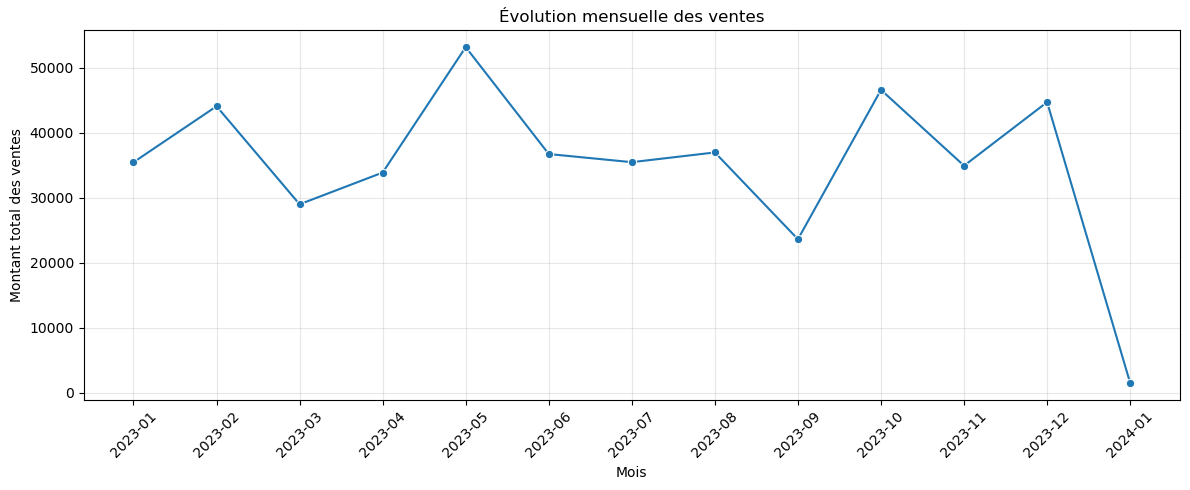

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_sales,
    x="YearMonth",
    y="Total_Sales",
    marker="o"
)

plt.title("Évolution mensuelle des ventes")
plt.xlabel("Mois")
plt.ylabel("Montant total des ventes")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    outputs_dir / "monthly_sales.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [42]:
best_month = monthly_sales.loc[
    monthly_sales["Total_Sales"].idxmax()
]

worst_month = monthly_sales.loc[
    monthly_sales["Total_Sales"].idxmin()
]

print("Meilleur mois :")
print(best_month)

print("\nMois avec les ventes les plus faibles :")
print(worst_month)

Meilleur mois :
YearMonth       2023-05
Total_Sales       53150
Transactions        105
Items_Sold          259
Name: 4, dtype: object

Mois avec les ventes les plus faibles :
YearMonth       2024-01
Total_Sales        1530
Transactions          2
Items_Sold            4
Name: 12, dtype: object


In [43]:
# Période couverte par les données
print("Première date :", df["Date"].min())
print("Dernière date :", df["Date"].max())

# Vérifier les transactions des mois extrêmes
print("\nPremières transactions :")
display(
    df.sort_values("Date")[
        ["Transaction ID", "Date", "Total Amount"]
    ].head()
)

print("\nDernières transactions :")
display(
    df.sort_values("Date")[
        ["Transaction ID", "Date", "Total Amount"]
    ].tail()
)

Première date : 2023-01-01 00:00:00
Dernière date : 2024-01-01 00:00:00

Premières transactions :


,Transaction ID,Date,Total Amount
521,522,2023-01-01,1500
179,180,2023-01-01,900
558,559,2023-01-01,1200
302,303,2023-01-02,90
978,979,2023-01-02,25



Dernières transactions :


,Transaction ID,Date,Total Amount
232,233,2023-12-29,600
804,805,2023-12-29,1500
856,857,2023-12-31,50
210,211,2024-01-01,1500
649,650,2024-01-01,30


In [44]:
monthly_check = (
    df.groupby("YearMonth")
      .agg(
          First_Date=("Date", "min"),
          Last_Date=("Date", "max"),
          Transactions=("Transaction ID", "nunique"),
          Total_Sales=("Total Amount", "sum")
      )
      .reset_index()
)

display(monthly_check.tail(3))

,YearMonth,First_Date,Last_Date,Transactions,Total_Sales
10,2023-11,2023-11-01,2023-11-30,78,34920
11,2023-12,2023-12-01,2023-12-31,91,44690
12,2024-01,2024-01-01,2024-01-01,2,1530


In [45]:
# Nombre de transactions par genre
gender_analysis = (
    df.groupby("Gender")
      .agg(
          Transactions=("Transaction ID", "nunique"),
          Total_Sales=("Total Amount", "sum"),
          Average_Sales=("Total Amount", "mean"),
          Items_Sold=("Quantity", "sum")
      )
      .reset_index()
)

gender_analysis["Sales_Share_Percent"] = (
    gender_analysis["Total_Sales"] / df["Total Amount"].sum() * 100
).round(2)

display(gender_analysis)

,Gender,Transactions,Total_Sales,Average_Sales,Items_Sold,Sales_Share_Percent
0,Female,510,232840,456.549020,1298,51.06
1,Male,490,223160,455.428571,1216,48.94


In [46]:
# Créer les tranches d'âge
df["Age_Group"] = pd.cut(
    df["Age"],
    bins=[17, 25, 35, 45, 100],
    labels=["18-25", "26-35", "36-45", "46+"]
)

age_analysis = (
    df.groupby("Age_Group", observed=False)
      .agg(
          Transactions=("Transaction ID", "nunique"),
          Total_Sales=("Total Amount", "sum"),
          Average_Sales=("Total Amount", "mean")
      )
      .reset_index()
)

display(age_analysis)

,Age_Group,Transactions,Total_Sales,Average_Sales
0,18-25,169,84550,500.295858
1,26-35,205,98480,480.390244
2,36-45,202,91870,454.801980
3,46+,424,181100,427.122642


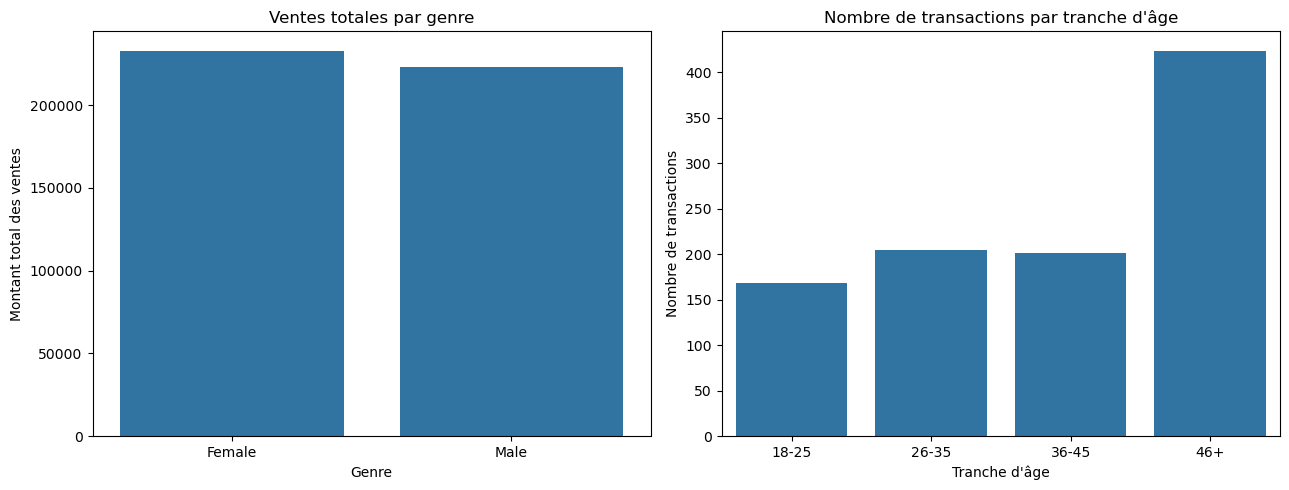

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(
    data=gender_analysis,
    x="Gender",
    y="Total_Sales",
    ax=axes[0]
)
axes[0].set_title("Ventes totales par genre")
axes[0].set_xlabel("Genre")
axes[0].set_ylabel("Montant total des ventes")

sns.barplot(
    data=age_analysis,
    x="Age_Group",
    y="Transactions",
    ax=axes[1]
)
axes[1].set_title("Nombre de transactions par tranche d'âge")
axes[1].set_xlabel("Tranche d'âge")
axes[1].set_ylabel("Nombre de transactions")

plt.tight_layout()
plt.savefig(
    outputs_dir / "sales_by_gender.png",
    dpi=300,
    bbox_inches="tight"
)
plt.savefig(
    outputs_dir / "transactions_by_age_group.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [48]:
sales_by_gender_category = pd.pivot_table(
    df,
    values="Total Amount",
    index="Product Category",
    columns="Gender",
    aggfunc="sum",
    fill_value=0
)

display(sales_by_gender_category)

Gender,Female,Male
Product Category,,
Beauty,74830,68685
Clothing,81275,74305
Electronics,76735,80170


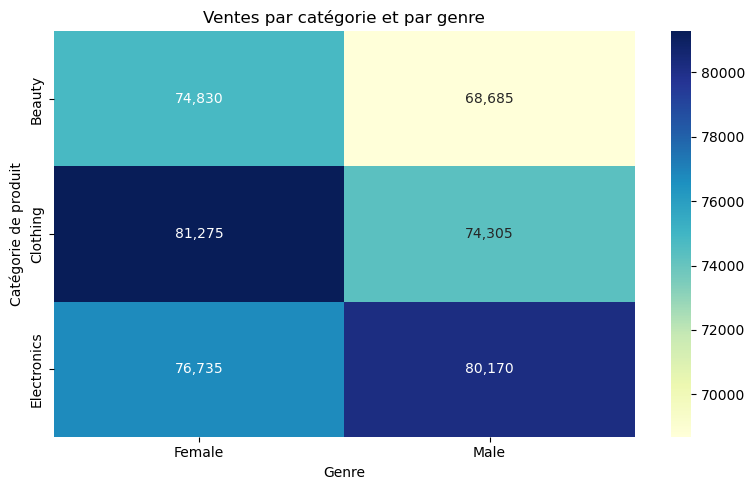

In [49]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    sales_by_gender_category,
    annot=True,
    fmt=",",
    cmap="YlGnBu"
)

plt.title("Ventes par catégorie et par genre")
plt.xlabel("Genre")
plt.ylabel("Catégorie de produit")
plt.tight_layout()
plt.savefig(
    outputs_dir / "sales_by_gender_category.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [50]:
sales_by_gender_category.to_csv(
    outputs_dir / "sales_by_gender_category.csv"
)

print("Tableau enregistré dans :", outputs_dir)

Tableau enregistré dans : C:\Users\LENOVO\Bureau\Projets\OIBSIP\DataAnalytics-L1-EDARetailSales\outputs


In [51]:
# Ventes par catégorie
sales_by_category.to_csv(
    outputs_dir / "sales_by_category.csv"
)

# Ventes par genre et catégorie
sales_by_gender_category.to_csv(
    outputs_dir / "sales_by_gender_category.csv"
)

print("Tableaux enregistrés dans :", outputs_dir)

Tableaux enregistrés dans : C:\Users\LENOVO\Bureau\Projets\OIBSIP\DataAnalytics-L1-EDARetailSales\outputs


In [52]:
print("RÉSUMÉ DE L'ANALYSE")
print("-" * 40)

print(f"Nombre de transactions : {df['Transaction ID'].nunique()}")
print(f"Chiffre d'affaires total : {df['Total Amount'].sum():,.0f}")
print(f"Panier moyen : {df['Total Amount'].mean():,.2f}")

best_category = df.groupby("Product Category")["Total Amount"].sum().idxmax()
best_month = df.groupby(df["Date"].dt.to_period("M"))["Total Amount"].sum().idxmax()

print(f"Catégorie la plus performante : {best_category}")
print(f"Meilleur mois : {best_month}")

RÉSUMÉ DE L'ANALYSE
----------------------------------------
Nombre de transactions : 1000
Chiffre d'affaires total : 456,000
Panier moyen : 456.00
Catégorie la plus performante : Electronics
Meilleur mois : 2023-05


In [53]:
from pathlib import Path

outputs_dir = Path(
    r"C:\Users\LENOVO\Bureau\Projets\OIBSIP\DataAnalytics-L1-EDARetailSales\outputs"
)

outputs_dir.mkdir(parents=True, exist_ok=True)

print("Dossier de sortie :", outputs_dir)
print("Dossier existant :", outputs_dir.exists())

Dossier de sortie : C:\Users\LENOVO\Bureau\Projets\OIBSIP\DataAnalytics-L1-EDARetailSales\outputs
Dossier existant : True


In [54]:
for file in sorted(outputs_dir.iterdir()):
    print(file.name)

monthly_sales.png
sales_by_category.csv
sales_by_category.png
sales_by_gender.png
sales_by_gender_category.csv
sales_by_gender_category.png
transactions_by_age_group.png
